In [90]:
import numpy as np
import matplotlib.pyplot as plt 
from scipy import optimize
import scipy.odr as odr

# M2 Gekoppelte Pendel

## Aufgabe 1: Schwingungsdauer $T_0$ beider Pendel

### Gemessen:
    - Position in m und Zeit in s
    - keine Kopplung zwischen den Pendeln, also einfach zwei freie Schwingungen
    
### Vorgehen:
    - Daten mit Unsicherheiten plotten
    - Fit erstellen mit ODR 
        - Fit Funktion: 
$$
x(t) = A \cdot \sin(\omega t +\Phi) + C
$$
    - Zur Funktion: Annahme Reibungsfrei 
    - $\omega_0$ durch Fit ink. Unsicherheit bekannt
    - dann durch  $T_0 = \frac{2 \pi}{\omega_0}$ berechnen
    
### Unsicherheiten:
    - Die Messung der Zeit besitzt einen Absolutfehler von $u_t = \pm 0.0005$
    - Die Messung der Position besitzt einen Absolutfehler von $u_p = \pm 0.001$
    - T_0 ist abhängig von einer fehlerbehafteten Größe. Fehlerfortpflanzung:
$$
u_{T_0} = \frac{2 \pi}{\omega_0 ^2} \cdot u_{\omega_0}
$$

In [91]:
# Kommas durch Punkte ersetzen
# erste Messung
infile = open("Nr_1_Schwingungsdauer.txt")
data = infile.read()
infile.close()
type(data)
new_data = data.replace(",", ".")
outfile = open("Nr_1_Schwingungsdauer.txt", "w")
outfile.write(new_data)
outfile.close()

In [92]:
# ertes Pendel
time_1, pos_1 = np.loadtxt("Nr_1_Schwingungsdauer.txt", 'float', skiprows= 1, unpack=True, usecols=(0,1)) 
time_1 = time_1.tolist()
time_1 = np.asarray(time_1)
pos_1 = pos_1.tolist()

pos_1 = np.asarray(pos_1)

n_time_1 = time_1[:240]
n_pos_1 = pos_1[:240]

# zweites Pendel
time_2, pos_2 = np.loadtxt("Nr_1_Schwingungsdauer.txt", 'float',  skiprows= 1, unpack=True, usecols=(2,3), max_rows = 519) 
time_2 = time_2.tolist()
time_2 = np.asarray(time_2)

pos_2 = pos_2.tolist()
pos_2 = np.asarray(pos_2)

n_time_2 = time_2[:240]
n_pos_2 = pos_2[:240]

In [93]:
# Unsicherheiten 
u_t = 0.0005
u_p = 0.001

In [94]:
def sinus(p, t):
    A = p[0]
    w = p[1]
    phi = p[2]
    C = p[3]
    temp = A*np.sin(w*t + phi) +C
    return temp

In [95]:
mymodel_1 = odr.Model(sinus)

mydata_1 = odr.RealData(n_time_1, n_pos_1, sx = u_t, sy = u_p)

myodr_1 = odr.ODR(mydata_1, mymodel_1, beta0=[0.3, 3.1, 0.1, 0.3])

myoutput_1 = myodr_1.run()

myoutput_1.pprint()
p_1 = [0.13876153, 2.54286054, 0.15693391, 0.35471186]
print()
mymodel_2 = odr.Model(sinus)

mydata_2 = odr.RealData(n_time_2, n_pos_2, sx = u_t, sy = u_p)

myodr_2 = odr.ODR(mydata_2, mymodel_2, beta0=[0.3, 3.1, 0.1, 0.3])

myoutput_2 = myodr_2.run()

myoutput_2.pprint()
p_2 = [0.12707389, 2.59578398, 1.40375687, 0.31115913]

Beta: [0.13875614 2.54284718 0.15696321 0.35469451]
Beta Std Error: [8.04994253e-05 4.38450347e-04 1.19833492e-03 5.74573105e-05]
Beta Covariance: [[ 8.31935927e-09  6.21549569e-09 -1.49094166e-08  4.92658871e-12]
 [ 6.21549569e-09  2.46800001e-07 -5.85064136e-07  6.67555432e-10]
 [-1.49094166e-08 -5.85064136e-07  1.84357475e-06  2.49590134e-10]
 [ 4.92658871e-12  6.67555432e-10  2.49590134e-10  4.23833136e-09]]
Residual Variance: 0.7789250667135638
Inverse Condition #: 0.0060307797469848585
Reason(s) for Halting:
  Sum of squares convergence

Beta: [0.12808452 2.54322396 1.42880325 0.31011076]
Beta Std Error: [6.59747490e-05 3.93519772e-04 1.11136428e-03 4.96948682e-05]
Beta Covariance: [[ 8.74724787e-09 -6.86353972e-09  1.85552432e-08  5.73489380e-10]
 [-6.86353972e-09  3.11206785e-07 -7.83979157e-07 -1.50991757e-08]
 [ 1.85552432e-08 -7.83979157e-07  2.48215449e-06  3.87240878e-08]
 [ 5.73489380e-10 -1.50991757e-08  3.87240878e-08  4.96294001e-09]]
Residual Variance: 0.4976042254436


Die Kreisfrequenz lautet 2.542847182320915 +/- 0.00039351977209788904

Maximaler relativer Fehler:
3.714710252600297e-05
0.00202020202020202


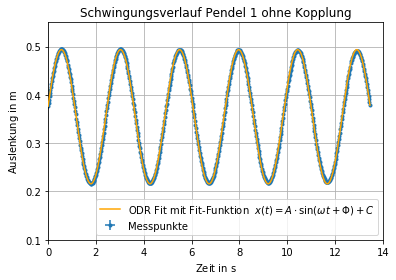

In [96]:
%matplotlib inline
plt.figure()
plt.errorbar(time_1, pos_1,xerr = u_t, yerr = u_p, fmt ='.',label = "Messpunkte", zorder = 2)
plt.plot(time_1, sinus(p_1, time_1), color = 'orange', linewidth = 1.5, zorder = 3, label = "ODR Fit mit Fit-Funktion  $x(t) = A \cdot \sin(\omega t +\Phi) + C$")
plt.grid(zorder = 1)
plt.xlim(0,14)
plt.ylim(0.1, 0.55)
plt.title("Schwingungsverlauf Pendel 1 ohne Kopplung")
plt.xlabel("Zeit in $\mathrm{s}$")
plt.ylabel("Auslenkung in $\mathrm{m}$")
plt.legend(loc = 'lower right')
plt.savefig('Schwingungsdauer Pendel 1.pdf')

print()
w_1 = myoutput_1.beta[1]
u_w_1 = myoutput_2.sd_beta[1]
print("Die Kreisfrequenz lautet " + str(w_1)+ " +/- " + str(u_w_1) )
print()
print("Maximaler relativer Fehler:")
print(u_t/time_1.max())
print(u_p/pos_1.max())


Die Kreisfrequent lautet 2.5432239593802666 +/- 0.00039351977209788904

Maximaler relativer Fehler:
4.826254826254827e-05
0.00228310502283105


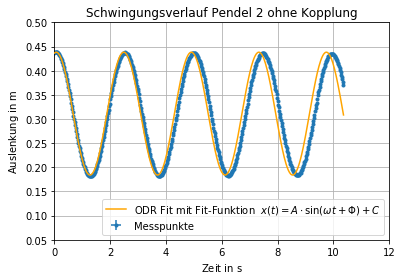

In [97]:
plt.figure()
plt.errorbar(time_2, pos_2, xerr = u_t, yerr = u_p, fmt = '.', label = "Messpunkte", zorder = 2)
plt.plot(time_2, sinus(p_2, time_2), color = 'orange', linewidth = 1.5, zorder = 3, label = "ODR Fit mit Fit-Funktion  $x(t) = A \cdot \sin(\omega t +\Phi) + C$")
plt.grid(zorder = 1)
plt.xlim(0,12)
plt.ylim(0.05, 0.5)
plt.title("Schwingungsverlauf Pendel 2 ohne Kopplung")
plt.xlabel("Zeit in $\mathrm{s}$")
plt.ylabel("Auslenkung in $\mathrm{m}$")
plt.legend(loc = 'lower right')
plt.savefig('Schwingungsdauer Pendel 2.pdf')

print()
w_2 = myoutput_2.beta[1]
u_w_2 = myoutput_2.sd_beta[1]
print("Die Kreisfrequent lautet " + str(w_2)+ " +/- " + str(u_w_2) )
print()
print("Maximaler relativer Fehler:")
print(u_t/time_2.max())
print(u_p/pos_2.max())

In [98]:
def u_T_0(w, u_w):
    return ((2 * np.pi)/w**2)*u_w

In [99]:
# Schwinungsdauer
T_0_P1 = (2*np.pi)/w_1
u_T_0_P1 = ((2*np.pi)/w_1**2)*u_w_1
T_0_P2 = (2*np.pi)/w_2
u_T_0_P2 = ((2*np.pi)/w_2**2)*u_w_2
print(T_0_P1)
print(u_T_0_P1)
print(T_0_P2)
print(u_T_0_P2)

2.470925249013501
0.0003823894521161194
2.4705591829634517
0.00038227615898642046


## Aufgabe 2 Feder 1
### Teil a) Schwebungsdauer $T_s$

### Gemessen:
    - Position in m und Zeit in s
    
### Vorgehen:
    - Daten mit Unsicherheiten plotten
    - Fit erstellen mit ODR 
        - Fit Funktion: (allgemeine Lösung für gekoppelte Pendel)
$$
x = C + a\sin(\omega_1 t + \varphi_1) \cdot \sin(\omega_2 t +\varphi_2)
$$
    - Zur Funktion: Annahme Reibungsfrei 
    - noch Unklar: was genau sagen \omega_1 und \omega_2 aus
        - \omega_1 ist die Schwebungsfrequenz
    - dann durch  $T_0 = \frac{2 \pi}{\omega}$ berechnen
    
### Unsicherheiten:
    - Die Messung der Zeit besitzt einen Absolutfehler von $u_t = \pm 0.0005$
    - Die Messung der Position besitzt einen Absolutfehler von $u_p = \pm 0.001$
    - T_0 ist abhängig von einer fehlerbehafteten Größe. Fehlerfortpflanzung:
$$
u_{T_0} = \frac{2 \pi}{\omega_0 ^2} \cdot u_{\omega_0}
$$

In [100]:
# Kommas durch Punkte ersetzen
# zweite Messung
infile = open("2a_feder1.txt")
data = infile.read()
infile.close()
type(data)
new_data = data.replace(",", ".")
outfile = open("2a_feder1.txt", "w")
outfile.write(new_data)
outfile.close()

# Daten richtig machen
time_f_1_a, pos_f_1_a = np.loadtxt("2a_feder1.txt", 'float', skiprows= 1, unpack=True, usecols=(0,1))

time_f_1_a = time_f_1_a.tolist()
time_f_1_a = np.asarray(time_f_1_a)

pos_f_1_a = pos_f_1_a.tolist()
pos_f_1_a = np.asarray(pos_f_1_a)

print(len(time_f_1_a))

1916


In [101]:
def kop_pen(p, t):
    A = p[0]
    alpha = p[1]
    w_1 = p[2]
    phi_1 = p[3]
    w_2 = p[4]
    phi_2 = p[5]
    temp = A + alpha*np.sin(w_1*t + phi_1)*np.sin(w_2*t + phi_2)
    return temp

In [102]:
def kop_pen_V2(p, t):
    A = p[0]
    alpha = p[1]
    w_1 = p[2]
    w_2 = p[3]
    temp = A + alpha*np.sin(0.5*(w_1- w_2)*t)*np.sin(0.5*(w_1 + w_2)*t)
    return temp

In [103]:
mymodel_f_1_a = odr.Model(kop_pen)

mydata_f_1_a = odr.RealData(time_f_1_a, pos_f_1_a, sx = u_t, sy = u_p)

myodr_f_1_a = odr.ODR(mydata_f_1_a, mymodel_f_1_a, beta0=[0.23887013, 0.11111582, 0.26,  1.28839292, 2.8, 1.53593303]) 
myoutput_f_1_a = myodr_f_1_a.run()

myoutput_f_1_a.pprint()
p_f_1_a = myoutput_f_1_a.beta

Beta: [0.34992613 0.05808191 0.26650121 2.03676333 2.82218053 2.899061  ]
Beta Std Error: [0.00017635 0.00035604 0.00054898 0.01152112 0.00055773 0.01284409]
Beta Covariance: [[ 5.23294402e-10  2.01801415e-11 -1.19532573e-12 -2.53672261e-10
  -2.86176212e-11  5.92932651e-10]
 [ 2.01801415e-11  2.13299870e-09  7.21373487e-11  1.05784819e-09
   3.61384516e-11 -9.62390328e-10]
 [-1.19532573e-12  7.21373487e-11  5.07111757e-09 -9.04422800e-08
   7.08308934e-11 -1.62239814e-09]
 [-2.53672261e-10  1.05784819e-09 -9.04422800e-08  2.23349076e-06
  -1.44553454e-09  3.50787844e-08]
 [-2.86176212e-11  3.61384516e-11  7.08308934e-11 -1.44553454e-09
   5.23419105e-09 -1.06123833e-07]
 [ 5.92932651e-10 -9.62390328e-10 -1.62239814e-09  3.50787844e-08
  -1.06123833e-07  2.77588392e-06]]
Residual Variance: 59.42992616475619
Inverse Condition #: 0.011452690983178299
Reason(s) for Halting:
  Sum of squares convergence



Die Kreisfrequenz lautet 0.26650120881755546 +/- 0.0005489773608848586

Maximaler relativer Fehler:
1.3054830287206268e-05
0.0024390243902439024


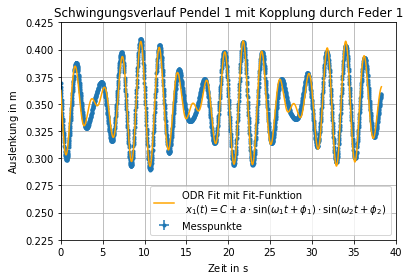

In [104]:
plt.figure()
plt.errorbar(time_f_1_a, pos_f_1_a, xerr = u_t, yerr = u_p, fmt = '.', label = "Messpunkte", zorder = 2)
plt.plot(time_f_1_a, kop_pen(p_f_1_a, time_f_1_a), color = 'orange', linewidth = 1.5, zorder = 3, label = 'ODR Fit mit Fit-Funktion \n $x_{1}(t) = C + a \cdot \sin(\omega_1 t + \phi_1) \cdot \sin(\omega_2 t +\phi_2)$')  
plt.grid(zorder = 1)
plt.xlim(0,40)
plt.ylim(0.225, 0.425)
plt.title("Schwingungsverlauf Pendel 1 mit Kopplung durch Feder 1")
plt.xlabel("Zeit in $\mathrm{s}$")
plt.ylabel("Auslenkung in $\mathrm{m}$")
plt.legend(loc = 'lower right')
plt.savefig('Schwebungsdauer Feder 1.pdf')
print()
w_f_1_a = myoutput_f_1_a.beta[2]
u_w_f_1_a = myoutput_f_1_a.sd_beta[2]
print("Die Kreisfrequenz lautet " + str(w_f_1_a)+ " +/- " + str(u_w_f_1_a) )
print()
print("Maximaler relativer Fehler:")
print(u_t/time_f_1_a.max())
print(u_p/pos_f_1_a.max())

In [105]:
# Schwebungsdauer
T_S_f_1_a = (2*np.pi)/w_f_1_a
u_T_S_f_1_a = u_T_0(w_f_1_a,u_w_f_1_a)
print(T_S_f_1_a)
print(u_T_S_f_1_a)
print(u_T_S_f_1_a/T_S_f_1_a)

23.576573386130505
0.04856640273285512
0.0020599432299786826


## Feder 2
### Teil a) Schwebungsdauer $T_s$

In [106]:
# Kommas durch Punkte ersetzen
# zweite Messung
infile = open("2a_feder2.txt")
data = infile.read()
infile.close()
type(data)
new_data = data.replace(",", ".")
outfile = open("2a_feder2.txt", "w")
outfile.write(new_data)
outfile.close()

# Daten richtig machen
time_f_2_a, pos_f_2_a = np.loadtxt("2a_feder2.txt", 'float', skiprows= 1, unpack=True, usecols=(0,1))

time_f_2_a = time_f_2_a.tolist()
time_f_2_a = np.asarray(time_f_2_a)

pos_f_2_a = pos_f_2_a.tolist()
pos_f_2_a = np.asarray(pos_f_2_a)

print(len(time_f_2_a))

1753


In [107]:
mymodel_f_2_a = odr.Model(kop_pen)

mydata_f_2_a = odr.RealData(time_f_2_a, pos_f_2_a, sx = u_t, sy = u_p)

myodr_f_2_a = odr.ODR(mydata_f_2_a, mymodel_f_2_a, beta0=[ 0.35444929, 0.05367997, 0.3497918, 1.47619122 ,2.68771359,  3.86774986])

myoutput_f_2_a = myodr_f_2_a.run()

myoutput_f_2_a.pprint()
p_f_2_a = myoutput_f_2_a.beta

Beta: [0.38608342 0.06275839 0.52283649 0.0455161  3.08511718 1.68526039]
Beta Std Error: [0.00022734 0.00044992 0.00074002 0.01468335 0.00069755 0.01436933]
Beta Covariance: [[ 5.72687927e-10  1.02479789e-11 -5.96999388e-11  7.34273564e-10
   1.02370548e-11 -9.64006694e-11]
 [ 1.02479789e-11  2.24297381e-09  2.89483985e-10 -5.31837901e-09
   7.54097846e-12 -9.85558233e-11]
 [-5.96999388e-11  2.89483985e-10  6.06781028e-09 -1.04343543e-07
  -5.91122200e-11  6.40295224e-10]
 [ 7.34273564e-10 -5.31837901e-09 -1.04343543e-07  2.38891000e-06
   6.39136015e-10 -6.38164930e-09]
 [ 1.02370548e-11  7.54097846e-12 -5.91122200e-11  6.39136015e-10
   5.39133572e-09 -9.62619137e-08]
 [-9.64006694e-11 -9.85558233e-11  6.40295224e-10 -6.38164930e-09
  -9.62619137e-08  2.28782147e-06]]
Residual Variance: 90.25072924904228
Inverse Condition #: 0.01425005507288348
Reason(s) for Halting:
  Sum of squares convergence



Die Kreisfrequenz lautet 0.5228364928080493 +/- 0.000740016420273253

Maximaler relativer Fehler:
1.4269406392694065e-05
0.0022123893805309734


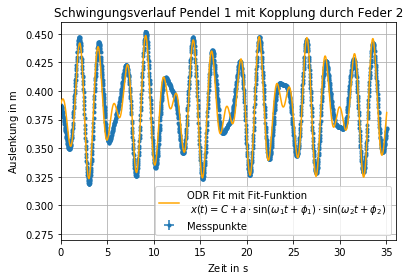

In [108]:
%matplotlib inline
plt.figure()
plt.errorbar(time_f_2_a, pos_f_2_a, xerr = u_t, yerr = u_p, fmt = '.', label = "Messpunkte", zorder = 2)
plt.plot(time_f_2_a, kop_pen(p_f_2_a, time_f_2_a), color = 'orange', linewidth = 1.5, zorder = 3, label = 'ODR Fit mit Fit-Funktion \n $x(t) = C + a \cdot \sin(\omega_1 t + \phi_1) \cdot \sin(\omega_2 t +\phi_2)$')  
plt.grid(zorder = 1)
plt.xlim(0,36)
plt.ylim(0.27, 0.46)
plt.title("Schwingungsverlauf Pendel 1 mit Kopplung durch Feder 2")
plt.xlabel("Zeit in $\mathrm{s}$")
plt.ylabel("Auslenkung in $\mathrm{m}$")
plt.legend(loc = 'lower right')
plt.savefig('Schwebungsdauer Feder 2.pdf')
print()
w_f_2_a = myoutput_f_2_a.beta[2]
u_w_f_2_a = myoutput_f_2_a.sd_beta[2]
print("Die Kreisfrequenz lautet " + str(w_f_2_a)+ " +/- " + str(u_w_f_2_a) )
print()
print("Maximaler relativer Fehler:")
print(u_t/time_f_2_a.max())
print(u_p/pos_f_2_a.max())

In [109]:
# Schwebungsdauer
T_S_f_2_a = (2*np.pi)/w_f_2_a
u_T_S_f_2_a = u_T_0(w_f_2_a,u_w_f_2_a)
print(T_S_f_2_a)
print(u_T_S_f_2_a)
print(u_T_S_f_2_a/T_S_f_2_a)

12.017495705844604
0.01700941742823847
0.0014153878515609612


### Teil b)

#### Messung der Grundschwingung $T_{gl}$ und $T_{geg}$

##### Gemessen:
    - Position in m und Zeit in s
    - einmal Gleichsinnig und einmal Gegensinnig
    
##### Vorgehen:
    - Daten mit Unsicherheiten plotten
    - Fit erstellen mit ODR 
        - Fit Funktion: sinus Fkt.
$$
x(t) = A \cdot \sin(\omega t +\Phi) + C
$$
    - Zur Funktion: Annahme Reibungsfrei 
    - noch Unklar: was genau sagen \omega_1 und \omega_2 aus
    - dann durch  $T_0 = \frac{2 \pi}{\omega}$ berechnen
    
##### Unsicherheiten:
    - Die Messung der Zeit besitzt einen Absolutfehler von $u_t = \pm 0.0005$
    - Die Messung der Position besitzt einen Absolutfehler von $u_p = \pm 0.001$
    - T_0 ist abhängig von einer fehlerbehafteten Größe. Fehlerfortpflanzung:
$$
u_{T_0} = \frac{2 \pi}{\omega_0 ^2} \cdot u_{\omega_0}
$$

### Feder 1

#### Gleichsinnig

In [110]:
# Kommas durch Punkte ersetzen
# zweite Messung
infile = open("2b_feder1.txt")
data = infile.read()
infile.close()
type(data)
new_data = data.replace(",", ".")
outfile = open("2b_feder1.txt", "w")
outfile.write(new_data)
outfile.close()

# Daten richtig machen
time_f_1_b_gl, pos_f_1_b_gl = np.loadtxt("2b_feder1.txt", 'float', skiprows= 1, unpack=True, usecols=(0,1), max_rows = 876)

time_f_1_b_gl = time_f_1_b_gl.tolist()
time_f_1_b_gl = np.asarray(time_f_1_b_gl)

pos_f_1_b_gl = pos_f_1_b_gl.tolist()
pos_f_1_b_gl = np.asarray(pos_f_1_b_gl)

print(len(time_f_1_b_gl))

876


In [111]:
mymodel_f_1_b_gl = odr.Model(sinus)

mydata_f_1_b_gl = odr.RealData(time_f_1_b_gl, pos_f_1_b_gl, sx = u_t, sy = u_p)

myodr_f_1_b_gl = odr.ODR(mydata_f_1_b_gl, mymodel_f_1_b_gl, beta0=[0.3, 3.1, 0.1, 0.3])

myoutput_f_1_b_gl = myodr_f_1_b_gl.run()

myoutput_f_1_b_gl.pprint()
p_f_1_b_gl = myoutput_f_1_b_gl.beta

Beta: [0.06455489 2.55416467 0.57693231 0.35048573]
Beta Std Error: [1.26820133e-04 3.94098110e-04 4.01802743e-03 9.02440655e-05]
Beta Covariance: [[ 2.27795457e-09 -4.38368490e-11 -1.28208843e-10 -2.95702915e-11]
 [-4.38368490e-11  2.19977040e-08 -1.95261176e-07 -4.04246885e-10]
 [-1.28208843e-10 -1.95261176e-07  2.28662235e-06  3.24031487e-09]
 [-2.95702915e-11 -4.04246885e-10  3.24031487e-09  1.15346907e-09]]
Residual Variance: 7.060433220130435
Inverse Condition #: 0.0015794013801162768
Reason(s) for Halting:
  Sum of squares convergence



Die Kreisfrequenz lautet 2.5541646668387354 +/- 0.0003940981098547621

Maximaler relativer Fehler:
2.857142857142857e-05
0.002403846153846154


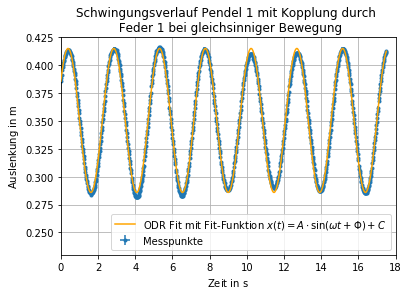

In [112]:
plt.figure()
plt.errorbar(time_f_1_b_gl, pos_f_1_b_gl, xerr = u_t, yerr = u_p, fmt = '.', label = "Messpunkte", zorder = 2)
plt.plot(time_f_1_b_gl, sinus(p_f_1_b_gl, time_f_1_b_gl), color = 'orange', linewidth = 1.5, zorder = 3, label = 'ODR Fit mit Fit-Funktion $x(t) = A \cdot \sin(\omega t +\Phi) + C$')  
plt.grid(zorder = 1)
plt.xlim(0,18)
plt.ylim(0.23, 0.425)
plt.title("Schwingungsverlauf Pendel 1 mit Kopplung durch \n Feder 1 bei gleichsinniger Bewegung")
plt.xlabel("Zeit in $\mathrm{s}$")
plt.ylabel("Auslenkung in $\mathrm{m}$")
plt.legend(loc = 'lower right')
plt.savefig('Gleichsinnige Bewegung Feder 1.pdf')
print()
w_f_1_b_gl = myoutput_f_1_b_gl.beta[1]
u_w_f_1_b_gl = myoutput_f_1_b_gl.sd_beta[1]
print("Die Kreisfrequenz lautet " + str(w_f_1_b_gl)+ " +/- " + str(u_w_f_1_b_gl) )
print()
print("Maximaler relativer Fehler:")
print(u_t/time_f_1_b_gl.max())
print(u_p/pos_f_1_b_gl.max())

In [113]:
# Schwingungsdauer Gleichsinnig Feder 1
T_f_1_b_gl = (2*np.pi)/w_f_1_b_gl
u_T_f_1_b_gl = u_T_0(w_f_1_b_gl,u_w_f_1_b_gl)
print(T_f_1_b_gl)
print(u_T_f_1_b_gl)

2.459976597732919
0.00037956524105135244


#### Gegensinnig

In [114]:
# Daten richtig machen
time_f_1_b_geg, pos_f_1_b_geg = np.loadtxt("2b_feder1.txt", 'float', skiprows= 1, unpack=True, usecols=(2,3), max_rows= 903)

time_f_1_b_geg = time_f_1_b_geg.tolist()
time_f_1_b_geg = np.asarray(time_f_1_b_geg)

pos_f_1_b_geg = pos_f_1_b_geg.tolist()
pos_f_1_b_geg = np.asarray(pos_f_1_b_geg)

print(len(time_f_1_b_geg))

903


In [115]:
mymodel_f_1_b_geg = odr.Model(sinus)

mydata_f_1_b_geg= odr.RealData(time_f_1_b_geg, pos_f_1_b_geg, sx = u_t, sy = u_p)

myodr_f_1_b_geg = odr.ODR(mydata_f_1_b_geg, mymodel_f_1_b_geg, beta0=[0.3, 3.1, 0.1, 0.3])

myoutput_f_1_b_geg = myodr_f_1_b_geg.run()

myoutput_f_1_b_geg.pprint()
p_f_1_b_geg = myoutput_f_1_b_geg.beta

Beta: [0.08212908 3.08712351 0.2294602  0.34984686]
Beta Std Error: [7.51444185e-05 1.80367244e-04 1.86659512e-03 5.35596964e-05]
Beta Covariance: [[ 2.19855977e-09  1.08494431e-10 -1.11003769e-09 -5.72747196e-12]
 [ 1.08494431e-10  1.26666030e-08 -1.13675014e-07  6.23560659e-11]
 [-1.11003769e-09 -1.13675014e-07  1.35657894e-06 -1.85539327e-10]
 [-5.72747196e-12  6.23560659e-11 -1.85539327e-10  1.11691734e-09]]
Residual Variance: 2.5683557518576117
Inverse Condition #: 0.0015851565571666324
Reason(s) for Halting:
  Sum of squares convergence



Die Kreisfrequenz lautet 3.087123512670895 +/- 0.0001803672438894163

Maximaler relativer Fehler:
2.7716186252771622e-05
0.002304147465437788


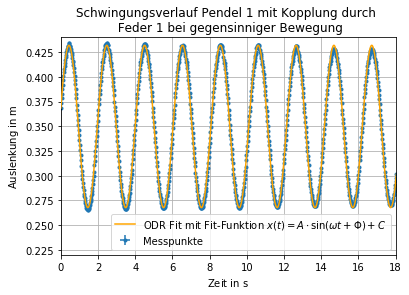

In [116]:
plt.figure()
plt.errorbar(time_f_1_b_geg, pos_f_1_b_geg, xerr = u_t, yerr = u_p, fmt = '.', label = "Messpunkte", zorder = 2)
plt.plot(time_f_1_b_geg, sinus(p_f_1_b_geg, time_f_1_b_geg), color = 'orange', linewidth = 1.5, zorder = 3, label = 'ODR Fit mit Fit-Funktion $x(t) = A \cdot \sin(\omega t +\Phi) + C$')  
plt.grid(zorder = 1)
plt.xlim(0,18)
plt.ylim(0.22, 0.44)
plt.title("Schwingungsverlauf Pendel 1 mit Kopplung durch \n Feder 1 bei gegensinniger Bewegung")
plt.xlabel("Zeit in $\mathrm{s}$")
plt.ylabel("Auslenkung in $\mathrm{m}$")
plt.legend(loc = 'lower right')
plt.savefig('Gegensinnige Bewegung Feder 1.pdf')
print()
w_f_1_b_geg = myoutput_f_1_b_geg.beta[1]
u_w_f_1_b_geg = myoutput_f_1_b_geg.sd_beta[1]
print("Die Kreisfrequenz lautet " + str(w_f_1_b_geg)+ " +/- " + str(u_w_f_1_b_geg) )
print()
print("Maximaler relativer Fehler:")
print(u_t/time_f_1_b_geg.max())
print(u_p/pos_f_1_b_geg.max())

In [117]:
# Schwingungsdauer Gegensinning Feder 1
T_f_1_b_geg = (2*np.pi)/w_f_1_b_geg
u_T_f_1_b_geg = u_T_0(w_f_1_b_gl,u_w_f_1_b_geg)
print(T_f_1_b_geg)
print(u_T_f_1_b_geg)

2.0352879570223434
0.00017371597247671272


### Feder 2

#### Gleichsinnig

In [118]:
# Kommas durch Punkte ersetzen
# zweite Messung
infile = open("2b_feder2.txt")
data = infile.read()
infile.close()
type(data)
new_data = data.replace(",", ".")
outfile = open("2b_feder2.txt", "w")
outfile.write(new_data)
outfile.close()

# Daten richtig machen
time_f_2_b_gl, pos_f_2_b_gl = np.loadtxt("2b_feder2.txt", 'float', skiprows= 1, unpack=True, usecols=(0,1))

time_f_2_b_gl = time_f_2_b_gl.tolist()
time_f_2_b_gl = np.asarray(time_f_2_b_gl)

pos_f_2_b_gl = pos_f_2_b_gl.tolist()
pos_f_2_b_gl = np.asarray(pos_f_2_b_gl)

print(len(time_f_2_b_gl))

1232


In [119]:
mymodel_f_2_b_gl = odr.Model(sinus)

mydata_f_2_b_gl = odr.RealData(time_f_2_b_gl, pos_f_2_b_gl, sx = u_t, sy = u_p)

myodr_f_2_b_gl = odr.ODR(mydata_f_2_b_gl, mymodel_f_2_b_gl, beta0=[0.3, 2.7, 0.1, 0.5])

myoutput_f_2_b_gl = myodr_f_2_b_gl.run()

myoutput_f_2_b_gl.pprint()
p_f_2_b_gl = myoutput_f_2_b_gl.beta

Beta: [0.05812951 2.56427208 1.72916335 0.38599291]
Beta Std Error: [1.09923320e-04 2.69499404e-04 3.79976426e-03 7.81436465e-05]
Beta Covariance: [[ 1.61921811e-09 -8.11963629e-11  1.07919788e-09 -6.85888262e-12]
 [-8.11963629e-11  9.73287849e-09 -1.18806260e-07 -2.05083341e-10]
 [ 1.07919788e-09 -1.18806260e-07  1.93481296e-06  2.55033727e-09]
 [-6.85888262e-12 -2.05083341e-10  2.55033727e-09  8.18300900e-10]]
Residual Variance: 7.4623277271457615
Inverse Condition #: 0.001330104902498309
Reason(s) for Halting:
  Sum of squares convergence



Die Kreisfrequenz lautet 2.5642720795168157 +/- 0.0002694994044767891

Maximaler relativer Fehler:
2.0308692120227456e-05
0.0022172949002217295


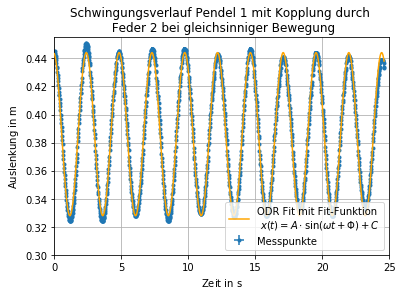

In [120]:
plt.figure()
plt.errorbar(time_f_2_b_gl, pos_f_2_b_gl, xerr = u_t, yerr = u_p, fmt = '.', label = "Messpunkte", zorder = 2)
plt.plot(time_f_2_b_gl, sinus(p_f_2_b_gl, time_f_2_b_gl), color = 'orange', linewidth = 1.5, zorder = 3, label = 'ODR Fit mit Fit-Funktion \n $x(t) = A \cdot \sin(\omega t +\Phi) + C$')  
plt.grid(zorder = 1)
plt.xlim(0,25)
plt.ylim(0.30, 0.455)
plt.title("Schwingungsverlauf Pendel 1 mit Kopplung durch \n Feder 2 bei gleichsinniger Bewegung")
plt.xlabel("Zeit in $\mathrm{s}$")
plt.ylabel("Auslenkung in $\mathrm{m}$")
plt.legend(loc = 'lower right')
plt.savefig('Gleichsinnige Bewegung Feder 2.pdf')
print()
w_f_2_b_gl = myoutput_f_2_b_gl.beta[1]
u_w_f_2_b_gl = myoutput_f_2_b_gl.sd_beta[1]
print("Die Kreisfrequenz lautet " + str(w_f_2_b_gl)+ " +/- " + str(u_w_f_2_b_gl) )
print()
print("Maximaler relativer Fehler:")
print(u_t/time_f_2_b_gl.max())
print(u_p/pos_f_2_b_gl.max())

In [121]:
# Schwingungsdauer Gleichsinnig Feder 2
T_f_2_b_gl = (2*np.pi)/w_f_2_b_gl
u_T_f_2_b_gl = u_T_0(w_f_2_b_gl,u_w_f_2_b_gl)
print(T_f_2_b_gl)
print(u_T_f_2_b_gl)

2.4502802792921736
0.00025751911481830374


#### Gegensinnig

In [122]:
# Daten richtig machen
time_f_2_b_geg, pos_f_2_b_geg = np.loadtxt("2b_feder2.txt", 'float', skiprows= 1, unpack=True, usecols=(2,3), max_rows = 1168)

time_f_2_b_geg = time_f_2_b_geg.tolist()
time_f_2_b_geg = np.asarray(time_f_2_b_geg)

pos_f_2_b_geg = pos_f_2_b_geg.tolist()
pos_f_2_b_geg = np.asarray(pos_f_2_b_geg)

print(len(time_f_2_b_geg))

1168


In [123]:
mymodel_f_2_b_geg = odr.Model(sinus)

mydata_f_2_b_geg= odr.RealData(time_f_2_b_geg, pos_f_2_b_geg, sx = u_t, sy = u_p)

myodr_f_2_b_geg = odr.ODR(mydata_f_2_b_geg, mymodel_f_2_b_geg, beta0=[0.3, 3.1, 0.1, 0.3])

myoutput_f_2_b_geg = myodr_f_2_b_geg.run()

myoutput_f_2_b_geg.pprint()
p_f_2_b_geg = myoutput_f_2_b_geg.beta

Beta: [-0.04225585  3.61147754 -3.56828652  0.38607407]
Beta Std Error: [7.57499818e-05 2.66700171e-04 3.56541792e-03 5.36422045e-05]
Beta Covariance: [[ 1.71423699e-09 -2.16620474e-11  4.38808116e-10  3.05223494e-11]
 [-2.16620474e-11  2.12496795e-08 -2.45364890e-07 -4.11339641e-11]
 [ 4.38808116e-10 -2.45364890e-07  3.79775270e-06 -1.21169670e-10]
 [ 3.05223494e-11 -4.11339641e-11 -1.21169670e-10  8.59644780e-10]]
Residual Variance: 3.347296661442658
Inverse Condition #: 0.0012293880144701485
Reason(s) for Halting:
  Sum of squares convergence



Die Kreisfrequenz lautet 3.611477540763144 +/- 0.00026670017109500695

Maximaler relativer Fehler:
2.1422450728363327e-05
0.0023148148148148147


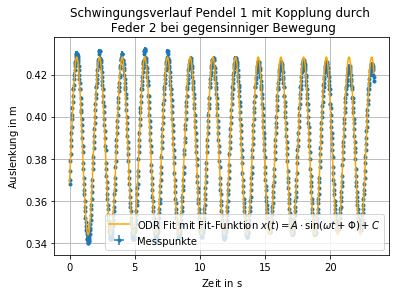

In [124]:
plt.figure()
plt.errorbar(time_f_2_b_geg, pos_f_2_b_geg, xerr = u_t, yerr = u_p, fmt = '.', label = "Messpunkte", zorder = 2)
plt.plot(time_f_2_b_geg, sinus(p_f_2_b_geg, time_f_2_b_geg), color = 'orange', linewidth = 1.5, zorder = 3, label = 'ODR Fit mit Fit-Funktion $x(t) = A \cdot \sin(\omega t +\Phi) + C$')  
plt.grid(zorder = 1)
#plt.xlim(0,18)
#plt.ylim(0.22, 0.44)
plt.title("Schwingungsverlauf Pendel 1 mit Kopplung durch \n Feder 2 bei gegensinniger Bewegung")
plt.xlabel("Zeit in $\mathrm{s}$")
plt.ylabel("Auslenkung in $\mathrm{m}$")
plt.legend(loc = 'lower right')
plt.savefig('Gegensinnige Bewegung Feder 2.pdf')
print()
w_f_2_b_geg = myoutput_f_2_b_geg.beta[1]
u_w_f_2_b_geg = myoutput_f_2_b_geg.sd_beta[1]
print("Die Kreisfrequenz lautet " + str(w_f_2_b_geg)+ " +/- " + str(u_w_f_2_b_geg) )
print()
print("Maximaler relativer Fehler:")
print(u_t/time_f_2_b_geg.max())
print(u_p/pos_f_2_b_geg.max())

In [125]:
# Schwingungsdauer Gegensinning Feder 2
T_f_2_b_geg = (2*np.pi)/w_f_2_b_geg
u_T_f_2_b_geg = u_T_0(w_f_2_b_gl,u_w_f_2_b_geg)
print(T_f_2_b_geg)
print(u_T_f_2_b_geg)

1.73978246749719
0.0002548443181743339


### Teil c) statischer Kopplungsgrad

#### Gemessen:
    - x_1 und x_2
        - x_1 ist die Auslenkung des ersten Pendels, wenn man das Pendel 2 händisch um x_2 auslenkt
        
#### Vorgehen:
    - Gesucht ist $\kappa$, der folgende Zusammenhang liefert die Gleichung
$$
\kappa = \frac{x_2}{x_1} \leftrightarrow x_2 = \kappa \cdot x_1
$$
    - in einem Diagramm $x_1$ gegen $x_2$ plotten und die Steigung durch fitten bestimmen. Dieser Wert ist dann $\kappa$
    
#### Unsicherheiten:
    - für x_1 und x_2 sind Unsicherheiten beim messen entstanden
        - Skala war auf Millimeter genau
           - Dreiecksverteilung
           
### Feder 1 

In [126]:
# Messpunkte
x_2_f_1 = np.array([0.4, 1, 1.6, 2.4, 3, 3.5])*1e-02 # in m, Pendel 1 folgte mit einem Ausschlag von x_2
x_1_f_1 = np.array([3, 6, 9, 12, 15, 18])*1e-02 # in m, Pendel 2 wurde um x_1 ausgelängt

In [127]:
# Unsicherheiten
a = 0.001 # in m 
u_x = a/(2*np.sqrt(6))
print(u_x)

0.00020412414523193154


In [128]:
def gerade(p, x):
    m,b = p
    return m*x +b

In [129]:
mymodel_f_1_c = odr.Model(gerade)

mydata_f_1_c = odr.RealData(x_1_f_1, x_2_f_1, sx = u_x, sy = u_x)

myodr_f_1_c = odr.ODR(mydata_f_1_c, mymodel_f_1_c, beta0=[0, 0])

myoutput_f_1_c = myodr_f_1_c.run()

myoutput_f_1_c.pprint()
p_f_1_c = myoutput_f_1_c.beta

Beta: [ 0.21241225 -0.00246995]
Beta Std Error: [0.00619656 0.00072397]
Beta Covariance: [[ 2.76483543e-06 -2.90307773e-07]
 [-2.90307773e-07  3.77401178e-08]]
Residual Variance: 13.887776206980353
Inverse Condition #: 0.048412405602833226
Reason(s) for Halting:
  Sum of squares convergence



Die Kopplungsgrad lautet 0.2124122490568233 +/- 0.006196564835838773

Maximaler relativer Fehler:
0.0011340230290662863
0.005832118435198043


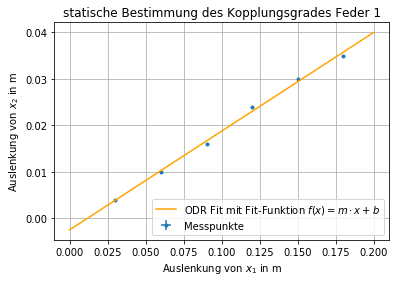

In [130]:
plt.figure()
plt.errorbar(x_1_f_1, x_2_f_1, xerr = u_x, yerr = u_x,fmt = '.', label = "Messpunkte", zorder = 2)
werte = np.linspace(0, 0.20, 20)
plt.plot(werte, gerade(p_f_1_c, werte), color = 'orange', linewidth = 1.5, zorder = 3, label = 'ODR Fit mit Fit-Funktion $f(x) = m \cdot x + b$')
plt.grid(zorder = 1)
plt.title("statische Bestimmung des Kopplungsgrades Feder 1")
plt.xlabel("Auslenkung von $x_1$ in $\mathrm{m}$")
plt.ylabel("Auslenkung von $x_2$ in $\mathrm{m}$")
plt.legend(loc = 'lower right')
plt.savefig('Kopplungsgrad Feder 1.pdf')
print()
k_c_f_1 = myoutput_f_1_c.beta[0]
u_k_c_f_1 = myoutput_f_1_c.sd_beta[0]
print("Die Kopplungsgrad lautet " + str(k_c_f_1) + " +/- " + str(u_k_c_f_1) )
print()
print("Maximaler relativer Fehler:")
print(u_x/x_1_f_1.max())
print(u_x/x_2_f_1.max())

### Feder 2

In [131]:
# Messpunkte
x_2_f_2 = np.array([0.7, 1.3, 2, 2.7, 4, 5.4])*1e-02 # in m
x_1_f_2 = np.array([2.3, 4.3, 6.3, 8.3, 12.3, 17.3])*1e-02 # in m

In [132]:
mymodel_f_2_c = odr.Model(gerade)

mydata_f_2_c = odr.RealData(x_1_f_2, x_2_f_2, sx = u_x, sy = u_x)

myodr_f_2_c = odr.ODR(mydata_f_2_c, mymodel_f_2_c, beta0=[0, 0])

myoutput_f_2_c = myodr_f_2_c.run()

myoutput_f_2_c.pprint()
p_f_2_c = myoutput_f_2_c.beta

Beta: [ 3.17499170e-01 -4.82907979e-05]
Beta Std Error: [0.00662237 0.00065286]
Beta Covariance: [[ 3.00170190e-06 -2.54192579e-07]
 [-2.54192579e-07  2.91726451e-08]]
Residual Variance: 14.610313946900522
Inverse Condition #: 0.048592534894590374
Reason(s) for Halting:
  Sum of squares convergence



Die Kopplungsgrad lautet 0.31749917021143886 +/- 0.006622371720494967

Maximaler relativer Fehler:
0.0011799083539418007
0.0037800767635542873


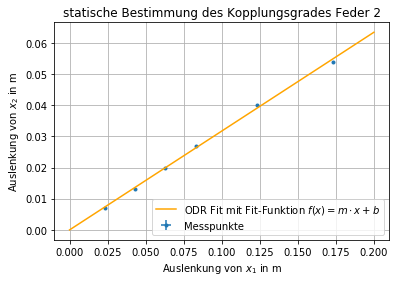

In [133]:
plt.figure()
plt.errorbar(x_1_f_2, x_2_f_2, xerr = u_x, yerr = u_x,fmt = '.', label = "Messpunkte", zorder = 2)
werte = np.linspace(0, 0.20, 20)
plt.plot(werte, gerade(p_f_2_c, werte), color = 'orange', linewidth = 1.5, zorder = 3, label = 'ODR Fit mit Fit-Funktion $f(x) = m \cdot x + b$')
plt.grid(zorder = 1)
plt.title("statische Bestimmung des Kopplungsgrades Feder 2")
plt.xlabel("Auslenkung von $x_1$ in $\mathrm{m}$")
plt.ylabel("Auslenkung von $x_2$ in $\mathrm{m}$")
plt.legend(loc = 'lower right')
plt.savefig('Kopplungsgrad Feder 2.pdf')
print()
k_c_f_2 = myoutput_f_2_c.beta[0]
u_k_c_f_2 = myoutput_f_2_c.sd_beta[0]
print("Die Kopplungsgrad lautet " + str(k_c_f_2)+ " +/- " + str(u_k_c_f_2) )
print()
print("Maximaler relativer Fehler:")
print(u_x/x_1_f_2.max())
print(u_x/x_2_f_2.max())

### Vergleich mit dynamischen Kopplungsgrad

#### Vorgehen:
    - einsetzen in die Formel:
$$
\kappa = \frac{T_{gl}^2 - T_{geg}^2}{T_{gl}^2 + T_{geg}^2}
$$

#### Unsicherheit: 
    - T_{gl} und T_{geg} unsicherheitsbelastet
    - Fehlerfortpflanzung lautet:
$$
u_{k} = \sqrt{\left(\frac{4 T_{gl} T_{geg}^2}{\left(T_{gl}^2 + T_{geg}^2 \right)^2} \cdot u_{T_{gl}} \right)^2 + \left(-\frac{4 T_{gl}^2 T_{geg}}{\left(T_{gl}^2 + T_{geg}^2 \right)^2} \cdot u_{T_{geg}} \right)^2}
$$

In [134]:
k_dyn_f_1 = (T_f_1_b_gl**2 - T_f_1_b_geg**2)/(T_f_1_b_gl**2 + T_f_1_b_geg**2) 
u_k_dyn_f_1 = np.sqrt( ((4 *T_f_1_b_gl* T_f_1_b_geg**2 * u_T_f_1_b_gl)/((T_f_1_b_gl**2 + T_f_1_b_geg**2)**2))**2 + ((-4* T_f_1_b_gl**2 *T_f_1_b_geg* u_T_f_1_b_geg)/((T_f_1_b_gl**2 + T_f_1_b_geg**2)**2))**2)
print("dynamischer Kopplungsgrad Feder 1: " + str(k_dyn_f_1) + " $\pm$ " + str(u_k_dyn_f_1))

k_dyn_f_2 = (T_f_2_b_gl**2 - T_f_2_b_geg**2)/(T_f_2_b_gl**2 + T_f_2_b_geg**2) 
u_k_dyn_f_2 = np.sqrt( ((4 *T_f_2_b_gl* T_f_2_b_geg**2 * u_T_f_2_b_gl)/((T_f_2_b_gl**2 + T_f_2_b_geg**2)**2))**2 + ((-4* T_f_2_b_gl**2 *T_f_1_b_geg* u_T_f_2_b_geg)/((T_f_2_b_gl**2 + T_f_2_b_geg**2)**2))**2)
print("dynamischer Kopplungsgrad Feder 2:  " + str(k_dyn_f_2) + " $\pm$ " + str(u_k_dyn_f_2))

dynamischer Kopplungsgrad Feder 1: 0.1872778011964837 $\pm$ 0.00017014570189180243
dynamischer Kopplungsgrad Feder 2:  0.3296560598533354 $\pm$ 0.0001791766558800295


### Teil d)
Formeln:
$$
T_S = \frac{4 \pi}{\omega_{geg} - \omega_{gl}} \Leftrightarrow \frac{4 \pi}{\frac{2 \pi}{T_{geg}} - \frac{2 \pi}{T_{gl}}} \Leftrightarrow \frac{2}{\frac{1}{T_{geg}} - \frac{1}{T_{gl}}} \Leftrightarrow\frac{2 T_{gl} T_{geg}}{T_{gl} - T_{geg}}
$$

Unsicherheit:
$$
u_{T_S} = \sqrt{\left(-\frac{2 T_{geg}^2}{(T_{gl} - T_{geg})^2} \cdot u_{T_{gl}} \right)^2 + \left(\frac{2 T_{gl}^2}{(T_{gl} - T_{geg})^2} \cdot u_{T_{geg}}\right)^2}
$$


In [139]:
# Schwebungsdauer T_S berechnen aus T_gl und T_geg

# Feder 1
T_S_f_1_calc = (2* T_f_1_b_gl*T_f_1_b_geg)/(T_f_1_b_gl - T_f_1_b_geg)
u_T_S_f_1_calc = np.sqrt(((2*T_f_1_b_geg**2 * u_T_f_1_b_gl)/((T_f_1_b_gl - T_f_1_b_geg))**2)**2 + ((2*T_f_1_b_gl**2 * u_T_f_1_b_geg)/((T_f_1_b_gl - T_f_1_b_geg))**2)**2)
print("Schwebungsdauer berechnen Feder 1: " + str(T_S_f_1_calc) + " +/- " + str(u_T_S_f_1_calc))
print("Schwebungsdauer gemessen Feder 1: " + str(T_S_f_1_a) + " +/- " + str(u_T_S_f_1_a))
print()
# Feder 2
T_S_f_2_calc = (2* T_f_2_b_gl*T_f_2_b_geg)/(T_f_2_b_gl - T_f_2_b_geg)
u_T_S_f_2_calc = np.sqrt(((2*T_f_2_b_geg**2 * u_T_f_2_b_gl)/((T_f_2_b_gl - T_f_2_b_geg))**2)**2 + ((2*T_f_2_b_gl**2 * u_T_f_2_b_geg)/((T_f_2_b_gl - T_f_2_b_geg))**2)**2)
print("Schwebungsdauer berechnen Feder 2: " + str(T_S_f_2_calc) + " +/- " + str(u_T_S_f_2_calc))
print("Schwebungsdauer gemessen Feder 2: " + str(T_S_f_2_a) + " +/- " + str(u_T_S_f_2_a))
print()
print(u_T_S_f_1_calc*100/T_S_f_1_calc)
print(u_T_S_f_1_a*100/T_S_f_1_a)
print(u_T_S_f_2_calc*100/T_S_f_2_calc)
print(u_T_S_f_2_a*100/T_S_f_2_a)

Schwebungsdauer berechnen Feder 1: 23.57850087793945 +/- 0.02097317368519701
Schwebungsdauer gemessen Feder 1: 23.576573386130505 +/- 0.04856640273285512

Schwebungsdauer berechnen Feder 2: 11.999909358191609 +/- 0.006803228598097524
Schwebungsdauer gemessen Feder 2: 12.017495705844604 +/- 0.01700941742823847

0.08895041204600061
0.20599432299786827
0.0566939998880356
0.1415387851560961


### Teil e)
$$
\frac{\Delta  \omega}{\omega_0} = \frac{\omega_{geg }- \omega_{gl}}{\omega_{geg}}
$$

$$
\frac{\Delta  \omega}{\omega_0} = \frac{4 \pi}{\omega_{gl}} \cdot \frac{\omega_{geg }- \omega_{gl}}{4 \pi} = 2 T_{gl} \cdot \frac{1}{T_S}
$$

$T_S$ hier der direkt gemessene Wert

Unsicherheit:
$$
u_{\frac{\Delta  \omega}{\omega_0}} = \sqrt{\left( \frac{2}{T_S} \cdot u_{T_{gl}} \right)^2 + \left( -\frac{2T_{gl}}{T_S^2} \cdot u_{T_{S}} \right)^2}
$$

In [136]:
# relative Frequenzaufspaltung aus T_S und T_gl

#Feder 1

rel_fre_f_1_T = 2*T_f_1_b_gl/T_S_f_1_a
u_rel_fre_f_1_T = np.sqrt(((2*u_T_f_1_b_gl)/T_S_f_1_a)**2 + ((2*T_S_f_1_a*u_T_S_f_1_a)/T_S_f_1_a**2)**2)
print("relative Frequenzaufspaltung Feder 1: " + str(rel_fre_f_1_T) +" +/- " + str(u_rel_fre_f_1_T))
#Feder 2

rel_fre_f_2_T = 2*T_f_2_b_gl/T_S_f_2_a
u_rel_fre_f_2_T = np.sqrt(((2*u_T_f_2_b_gl)/T_S_f_2_a)**2 + ((2*T_S_f_2_a*u_T_S_f_2_a)/T_S_f_2_a**2)**2)
print("relative Frequenzaufspaltung Feder 2: " + str(rel_fre_f_2_T) +" +/- " + str(u_rel_fre_f_2_T))

relative Frequenzaufspaltung Feder 1: 0.20867973962493297 +/- 0.004120012279938576
relative Frequenzaufspaltung Feder 2: 0.4077855052780258 +/- 0.0028311001104398626


## Aufgabe 3

Formeln: 
$$
\frac{\Delta  \omega}{\omega_0} = \sqrt{\frac{1+ \kappa}{1- \kappa}} -1
$$ 
mit 
$$
\frac{\Delta  \omega}{\omega_0} = \kappa + \frac{1}{2}\kappa^2 + \frac{1}{2}\kappa^3 
$$
vergleichen und dem berechneten Wert durch T_S und T_gl

Unsicherheiten:
ohne Närhung
$$
u_{\frac{\Delta  \omega}{\omega_0}} = \frac{1}{(1-\kappa)^2\sqrt{\frac{1+\kappa}{1-\kappa}}} \cdot u_{\kappa}
$$

mit Nährung
$$
u_{\frac{\Delta  \omega}{\omega_0}_N} = (1 + \kappa + \frac{3}{2}\kappa^2) \cdot u_{\kappa}
$$

In [137]:
# Feder 1

# ohne Nährung
rel_fre_f_1_k = np.sqrt((1+k_c_f_1)/(1-k_c_f_1))-1
u_rel_fre_f_1_k = u_k_c_f_1/((1-k_c_f_1)**2 * np.sqrt((1+k_c_f_1)/(1-k_c_f_1)))

# mit Nährung
rel_fre_f_1_k_N = k_c_f_1 + 0.5*k_c_f_1**2 + 0.5*k_c_f_1**3
u_rel_fre_f_1_k_N = (1+ k_c_f_1**2 + 1.5*k_c_f_1**2)*u_k_c_f_1

print("rel. Frequenzaufspaltung Feder 1, berechnet durch T_S und T_gl: " + str(rel_fre_f_1_T) +" +/- " + str(u_rel_fre_f_1_T))
print("rel. Frequenzaufspaltung Feder 1, berechnet durch kappa: " + str(rel_fre_f_1_k) +" +/- " + str(u_rel_fre_f_1_k))
print("rel. Frequenzaufspaltung Feder 1, berechnet durch kappa mit Nährung: " + str(rel_fre_f_1_k_N) +" +/- " + str(u_rel_fre_f_1_k_N))
print()
# Feder 2

# ohne Nährung
rel_fre_f_2_k = np.sqrt((1+k_c_f_2)/(1-k_c_f_2))-1
u_rel_fre_f_2_k = u_k_c_f_2/((1-k_c_f_2)**2 * np.sqrt((1+k_c_f_2)/(1-k_c_f_2)))

# mit Nährung
rel_fre_f_2_k_N = k_c_f_2 + 0.5*k_c_f_2**2 + 0.5*k_c_f_2**3
u_rel_fre_f_2_k_N = (1+ k_c_f_2**2 + 1.5*k_c_f_2**2)*u_k_c_f_2

print("rel. Frequenzaufspaltung Feder 2, berechnet durch T_S und T_gl: " + str(rel_fre_f_2_T) +" +/- " + str(u_rel_fre_f_2_T))
print("rel. Frequenzaufspaltung Feder 2, berechnet durch kappa: " + str(rel_fre_f_2_k) +" +/- " + str(u_rel_fre_f_2_k))
print("rel. Frequenzaufspaltung Feder 2, berechnet durch kappa mit Nährung: " + str(rel_fre_f_2_k_N) +" +/- " + str(u_rel_fre_f_2_k_N))

rel. Frequenzaufspaltung Feder 1, berechnet durch T_S und T_gl: 0.20867973962493297 +/- 0.004120012279938576
rel. Frequenzaufspaltung Feder 1, berechnet durch kappa: 0.2407254228773641 +/- 0.008051511374559206
rel. Frequenzaufspaltung Feder 1, berechnet durch kappa mit Nährung: 0.23976364109283035 +/- 0.006895521293237689

rel. Frequenzaufspaltung Feder 2, berechnet durch T_S und T_gl: 0.4077855052780258 +/- 0.0028311001104398626
rel. Frequenzaufspaltung Feder 2, berechnet durch kappa: 0.3893881270550892 +/- 0.010232543597772885
rel. Frequenzaufspaltung Feder 2, berechnet durch kappa mit Nährung: 0.3839048984699332 +/- 0.008291304145049552
